### cities_10记录了十个沿海省份的经济指标，通过降维方法对各省、市经济发展情况

变量含义如下：

|变量|含义|
|:--:|:--:|
|AREA|地区|
|X1|GDP|
|X2|人均GDP|
|X3|工业增加值|
|X4|第三产业增加值|
|X5|固定资产投资|
|X6|基本建设投资|
|X7|社会消费品零售总额|
|X8|海关出口总额|
|X9|地方财政收入|

In [1]:
%matplotlib inline

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

pd.set_option('display.max_columns', 8)

In [2]:
cities = pd.read_csv("cities_10.csv", encoding='gbk')
cities.head()

,AREA,X1,X2,X3,...,X6,X7,X8,X9
0,辽宁,5458.2,13000,1376.2,...,529.0,2258.4,123.7,399.7
1,山东,10550.0,11643,3502.5,...,1070.7,3181.9,211.1,610.2
2,河北,6076.6,9047,1406.7,...,597.1,1968.3,45.9,302.3
3,天津,2022.6,22068,822.8,...,361.9,941.4,115.7,171.8
4,江苏,10636.3,14397,3536.3,...,1141.3,3215.8,384.7,643.7


In [3]:
cities.loc[:, 'X1':].corr(method='pearson').head()

,X1,X2,X3,X4,...,X6,X7,X8,X9
X1,1.000000,-0.094292,0.966506,0.979238,...,0.921680,0.941148,0.637458,0.825568
X2,-0.094292,1.000000,0.112726,0.074167,...,0.093483,-0.042776,0.081195,0.273145
X3,0.966506,0.112726,1.000000,0.985373,...,0.939194,0.935196,0.704714,0.898016
X4,0.979238,0.074167,0.985373,1.000000,...,0.939720,0.962267,0.713890,0.913364
X5,0.922984,0.214052,0.963159,0.972862,...,0.971337,0.937109,0.716722,0.934549


### 主成分分析（预先进行标准化）
- [数据标准化参考](http://www.cnblogs.com/chaosimple/p/4153167.html)

In [4]:
from sklearn.preprocessing import StandardScaler

n_components = 2

scaler = StandardScaler()
scale_cities = scaler.fit_transform(cities.loc[:, 'X1':])

pca = PCA(n_components=n_components)
pca_scores = pca.fit_transform(scale_cities)
print('Cumsum of explained variance ratio: ', 
      pca.explained_variance_ratio_.cumsum())

Cumsum of explained variance ratio:  [0.80112955 0.92327887]


In [5]:
pca_scores = pd.DataFrame(pca_scores, columns=['Gross', 'Avg'])
scale_pca_cities = cities.join(pca_scores)
scale_pca_cities.head()

,AREA,X1,X2,X3,...,X8,X9,Gross,Avg
0,辽宁,5458.2,13000,1376.2,...,123.7,399.7,-1.189451,-0.310922
1,山东,10550.0,11643,3502.5,...,211.1,610.2,2.064157,-0.748544
2,河北,6076.6,9047,1406.7,...,45.9,302.3,-1.437690,-0.806697
3,天津,2022.6,22068,822.8,...,115.7,171.8,-3.230397,0.845198
4,江苏,10636.3,14397,3536.3,...,384.7,643.7,2.368927,-0.444810


In [6]:
# 主成分的业务解释
print(pca.components_)

[[ 0.35368214  0.04055515  0.36414818  0.3675844   0.36591717  0.35211896
   0.36441914  0.29756458  0.35540527]
 [-0.21219156  0.94277836 -0.00984533 -0.04537684  0.09521286 -0.02302652
  -0.13524072  0.04804689  0.18382995]]


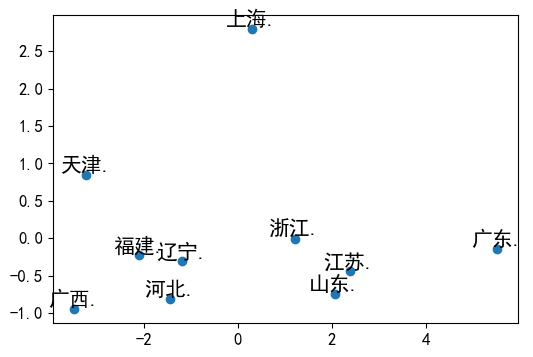

In [7]:
from pylab import mpl

mpl.rcParams['font.sans-serif'] = ['SimHei'] # 指定默认字体
mpl.rcParams['axes.unicode_minus'] = False   # 解决保存图像是负号'-'显示为方块的问题

def scatter(x, y, labels, **kw):
    plt.figure(figsize=(6, 4))
    plt.yticks(size=12)
    plt.xticks(size=12)
    plt.scatter(x, y)
    for xx, yy, label in zip(x, y, labels):
        plt.text(xx, yy, '%s.' % label, 
                 ha='center', va='bottom', **kw)
    plt.show()

x = scale_pca_cities['Gross']
y = scale_pca_cities['Avg']
labels = scale_pca_cities['AREA']
scatter(x, y, labels, fontsize=15)

### *稀疏主成分分析 SparsePCA

[SparsePCA文档说明](http://scikit-learn.org/stable/modules/generated/sklearn.decomposition.SparsePCA.html#sklearn.decomposition.SparsePCA)

In [8]:
from sklearn.decomposition import SparsePCA
alpha = 0.5
spca = SparsePCA(n_components=n_components, alpha=alpha)
spca.fit(scale_cities)
pd.DataFrame(spca.components_)

,0,1,2,3,...,5,6,7,8
0,0.356556,0.000000,0.366709,0.371198,...,0.352518,0.368163,0.285714,0.351946
1,-0.009869,0.998117,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.060533


选择合适的稀疏度

In [9]:
from functools import reduce

n_cols = scale_cities.shape[1]
spca_with_alpha = []

for i in np.arange(0.1, 1, 0.05):
    spca = SparsePCA(n_components=n_components, alpha=i)
    spca.fit(scale_cities)
    components_ = pd.DataFrame(spca.components_).T
    diff = np.count_nonzero(components_) - n_cols
    spca_with_alpha.append((i, diff))

selector = pd.DataFrame(spca_with_alpha)
selector.T

,0,1,2,3,...,14,15,16,17
0,0.1,0.15,0.2,0.25,...,0.8,0.85,0.9,0.95
1,5.0,4.00,4.0,4.00,...,0.0,0.00,0.0,0.00


In [10]:
spca_ = SparsePCA(n_components=n_components, alpha=0.65).fit(scale_cities)
pd.DataFrame(spca_.components_)

,0,1,2,3,...,5,6,7,8
0,0.35563,0.0,0.367331,0.372,...,0.352239,0.368369,0.28092,0.354282
1,0.00000,1.0,0.000000,0.000,...,0.000000,0.000000,0.00000,0.000000


In [11]:
scale_spca_cities = pd.DataFrame(spca_.transform(scale_cities), columns=['Gross', 'Avg'])
scale_spca_cities

,Gross,Avg
0,-1.162217,-0.332571
1,2.082519,-0.478368
2,-1.389567,-0.757284
3,-3.236252,0.641699
4,2.367343,-0.182477
5,0.180205,2.635688
6,1.204338,0.050991
7,-2.070122,-0.277777
8,5.430404,-0.114467
9,-3.406652,-1.185434


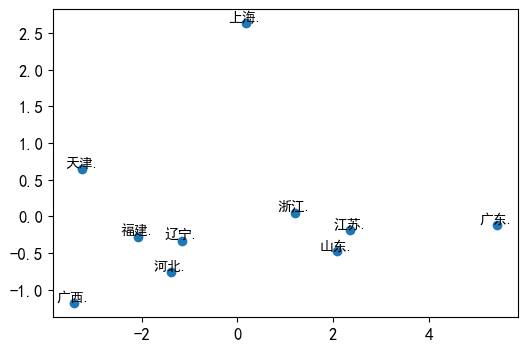

In [12]:
x = scale_spca_cities['Gross']
y = scale_spca_cities['Avg']
label = cities['AREA']

scatter(x, y, label)

### 因子分析

pip install fa_kit first！

- 使用fa_kit包，参考https://github.com/bmcmenamin/fa_kit

- 1、导入包，并对输入的数据进行主成分提取。

In [13]:
from fa_kit import FactorAnalysis
from fa_kit import plotting as fa_plotting

fa = FactorAnalysis.load_data_samples(
        scale_cities,
        preproc_demean=True,
        preproc_scale=True
        )
fa.extract_components()

- 2、设定提取主成分的方式。默认为“broken_stick”方法，建议使用“top_n”法

In [14]:
fa.find_comps_to_retain(method='top_n',num_keep=2)

array([0, 1], dtype=int64)

- 3、通过最大方差法进行因子旋转

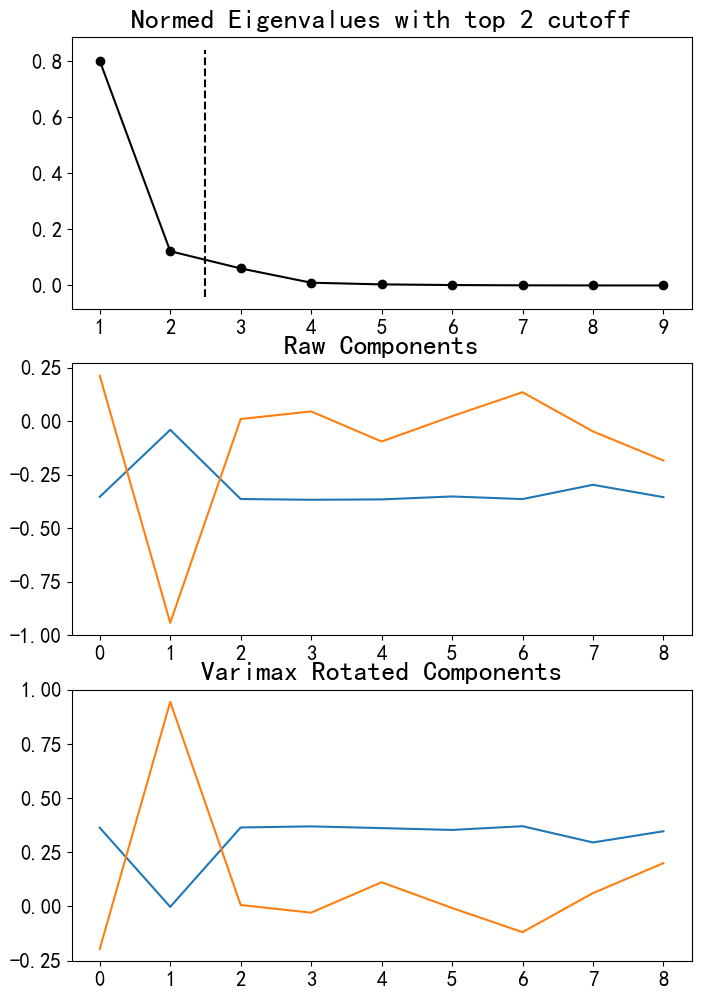

In [15]:
from pylab import mpl

mpl.rcParams['axes.titlesize'] = 20    #  指定title大小
mpl.rcParams['xtick.labelsize'] = 15   #  指定x刻度大小
mpl.rcParams['ytick.labelsize'] = 15   #  指定y刻度大小

fa.rotate_components(method='varimax') #  最大方差因子旋转
fa_plotting.graph_summary(fa)          #  绘制因子载荷矩阵与原始变量的关系

plt.show()

- 4、获取因子得分

In [16]:
print(fa.comps['rot'])

[[ 0.36287997 -0.19604704]
 [-0.00194704  0.94364822]
 [ 0.36422208  0.00656524]
 [ 0.36925509 -0.02877546]
 [ 0.36125764  0.11159649]
 [ 0.35279873 -0.00714435]
 [ 0.37014035 -0.11869071]
 [ 0.29509869  0.06139991]
 [ 0.34676526  0.19965023]]


In [17]:
fa_scores = fa.get_component_scores(scale_cities)  # 因子得分
# Equals to ```np.dot(scale_cities, fa_comps)```

cities_factor_analysis = cities.join(
    pd.DataFrame(fa_scores, columns=['Gross', 'Avg']))
cities_factor_analysis.to_csv('cities_FA_score.csv', index=False)
cities_factor_analysis.head()

,AREA,X1,X2,X3,...,X8,X9,Gross,Avg
0,辽宁,5458.2,13000,1376.2,...,123.7,399.7,-1.174241,-0.364178
1,山东,10550.0,11643,3502.5,...,211.1,610.2,2.095775,-0.654819
2,河北,6076.6,9047,1406.7,...,45.9,302.3,-1.399899,-0.870629
3,天津,2022.6,22068,822.8,...,115.7,171.8,-3.265185,0.698849
4,江苏,10636.3,14397,3536.3,...,384.7,643.7,2.386557,-0.337666


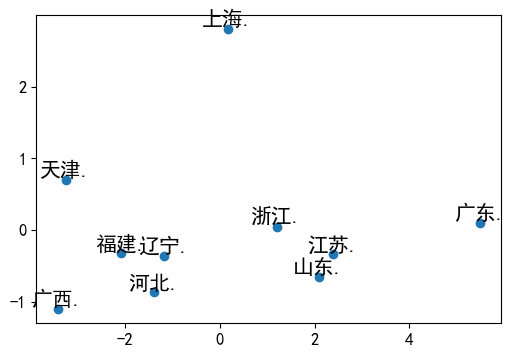

In [18]:
x = cities_factor_analysis['Gross']
y = cities_factor_analysis['Avg']
label = cities_factor_analysis['AREA']

scatter(x, y, label,fontsize=15)

### 层次聚类

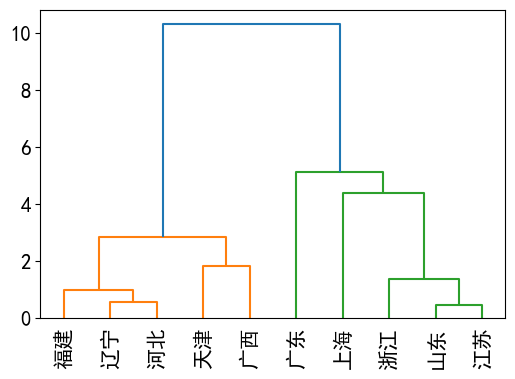

In [19]:
import scipy.cluster.hierarchy as sch

#  生成点与点之间的欧式距离矩阵
distMat = sch.distance.pdist(
    cities_factor_analysis[['Gross','Avg']],'euclidean') 

#  ward法进行层次聚类
Z = sch.linkage(distMat, method='ward') 

#  生成聚类树状图
fig, ax = plt.subplots(figsize=(6, 4)) 
P = sch.dendrogram(
    Z,                                               
    ax=ax,                                           # 设置绘制的轴
    labels=cities_factor_analysis['AREA'].tolist(),  # 设置标签
    leaf_font_size=15,                               # 设置标签字体大小
    leaf_rotation=90                                 # 设置标签字体方向
)  

plt.savefig('plot_dendrogram1.png')
plt.show()

In [20]:
labels = sch.cut_tree(Z, n_clusters=2)
cities_factor_analysis['cluster'] = labels

#  获取每个簇的中心
cities_factor_analysis.loc[:, 'X1':'X9'].groupby(
    cities_factor_analysis['cluster']).mean().T

cluster,0,1
X1,4138.96,9206.96
X2,12537.40,19653.40
X3,1003.96,3163.22
X4,1633.14,3686.52
X5,937.58,2379.68
X6,447.72,1089.48
X7,1571.38,3264.80
X8,94.82,610.84
X9,266.68,746.28
